**Student Name:** Shelia Howard  
**Course:** DSC680-T302 Applied Data Science (2271-1)  
**Assignment:** Term Project - Milestone 2  
**Due Date:** 9/27/2026

# Hospital Readmission Risk: Classifying Elevated Excess Readmission Ratios Under the CMS HRRP

## Purpose
This notebook reproduces the data preparation, exploratory analysis, leakage-safe classification, validation, and visualizations described in the Milestone 2 white paper. The binary target is **elevated Excess Readmission Ratio (ERR)**, defined as an ERR greater than 1.0.

### Research questions
1. How does the prevalence of ERR > 1.0 vary across HRRP conditions and states?
2. Can condition, state, and discharge volume classify ERR > 1.0 without same-period outcome-derived variables?
3. Does model performance differ materially by HRRP condition?


## Data Source and Reproducibility

This project uses the **FY 2026 Hospital Readmissions Reduction Program (HRRP) Hospital** dataset published by the Centers for Medicare & Medicaid Services (CMS).

**Source:**  
Centers for Medicare & Medicaid Services, Provider Data Catalog  
Hospital Readmissions Reduction Program  
https://data.cms.gov/provider-data/dataset/9n3s-kdb3

**Source file used in this notebook:**  
`FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv`

The file should be downloaded from the CMS Provider Data Catalog and saved in the same directory as this notebook, unless the file path is modified in the code.

The CMS HRRP dataset includes hospital-level, condition-specific information such as facility identifier, state, measure name, number of discharges, excess readmission ratio, predicted readmission rate, expected readmission rate, and number of readmissions.

For reproducibility, the original CMS source file should be retained without manual changes. All cleaning, filtering, handling of suppressed values, feature preparation, and modeling steps are performed within this notebook so that the analysis can be reproduced from the original downloaded file.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import sys
import sklearn
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.11.16
NumPy: 2.4.6
pandas: 3.0.6
scikit-learn: 1.9.1


## 1. Data acquisition
The primary source is the CMS Provider Data Catalog HRRP file. The direct CSV link below is the FY 2026 resource published in the federal catalog. If internet access is unavailable, place the CSV in the same folder as this notebook and name it `FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv`.

In [2]:
HRRP_URL = (
    "https://data.cms.gov/provider-data/sites/default/files/resources/"
    "a171bc36c488d3e0dc33ec63abb469a6_1770163617/"
    "FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv"
)
LOCAL_FILE = Path("FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv")

try:
    df_raw = pd.read_csv(HRRP_URL, dtype={"Facility ID": "string"})
    source_used = "CMS direct download"
except Exception as exc:
    if not LOCAL_FILE.exists():
        raise FileNotFoundError(
            "Could not download the CMS file. Download it manually from the CMS Provider Data Catalog "
            "and save it beside this notebook as FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv"
        ) from exc
    df_raw = pd.read_csv(LOCAL_FILE, dtype={"Facility ID": "string"})
    source_used = str(LOCAL_FILE)

print("Source:", source_used)
print("Shape:", df_raw.shape)
df_raw.head()

Source: CMS direct download
Shape: (18330, 12)


,Facility Name,Facility ID,State,Measure Name,Number of Discharges,Footnote,Excess Readmission Ratio,Predicted Readmission Rate,Expected Readmission Rate,Number of Readmissions,Start Date,End Date
0,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-HIP-KNEE-HRRP,NaN,NaN,0.9875,4.5734,4.6311,Too Few to Report,07/01/2021,06/30/2024
1,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-CABG-HRRP,137.0,NaN,0.9531,10.3960,10.9078,13,07/01/2021,06/30/2024
2,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-AMI-HRRP,273.0,NaN,0.9370,13.2998,14.1948,33,07/01/2021,06/30/2024
3,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-COPD-HRRP,122.0,NaN,0.9823,16.6384,16.9389,19,07/01/2021,06/30/2024
4,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-PN-HRRP,507.0,NaN,0.9871,15.7529,15.9591,79,07/01/2021,06/30/2024


## 2. Cleaning and preparation
CMS uses strings such as `N/A` and `Too Few to Report` in suppressed or unavailable cells. These values are treated as missing, never as zeros. Column names are standardized to snake_case. The target is created only when ERR is observed. Same-period predicted rate, expected rate, and number of readmissions are **not** model inputs because they are mathematically or operationally tied to the outcome.

In [3]:
df = df_raw.copy()
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True)
              .str.strip("_"))

missing_tokens = ["N/A", "Too Few to Report", "Not Available", ""]
df = df.replace(missing_tokens, np.nan)

numeric_cols = [
    "number_of_discharges", "excess_readmission_ratio",
    "predicted_readmission_rate", "expected_readmission_rate",
    "number_of_readmissions"
]
for c in numeric_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Normalize category labels.
df["condition"] = (df["measure_name"].str.replace("READM-30-", "", regex=False)
                   .str.replace("-HRRP", "", regex=False))

df["elevated_err"] = np.where(
    df["excess_readmission_ratio"].notna(),
    (df["excess_readmission_ratio"] > 1.0).astype(int),
    np.nan
)

# Check for exact duplicate rows before modeling.
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows before cleaning: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates().copy()

print(f"Rows after duplicate check: {len(df):,}")
print("Observed ERR rows:", df["excess_readmission_ratio"].notna().sum())
print("Target prevalence among observed ERR rows:", df["elevated_err"].mean())
df.isna().mean().sort_values(ascending=False).head(10)

Exact duplicate rows before cleaning: 0
Rows after duplicate check: 18,330
Observed ERR rows: 11720
Target prevalence among observed ERR rows: 0.48148464163822524


footnote                      0.618822
number_of_readmissions        0.561538
number_of_discharges          0.550355
expected_readmission_rate     0.360611
excess_readmission_ratio      0.360611
predicted_readmission_rate    0.360611
elevated_err                  0.360611
measure_name                  0.000000
facility_name                 0.000000
facility_id                   0.000000
dtype: float64

### Duplicate Record Handling

The dataset was checked for exact duplicate rows before analysis. Only records that were identical across all columns were considered duplicates and removed, if any were present. Multiple records for the same hospital are expected in the HRRP dataset because a hospital may have separate observations for different readmission measures or conditions. Therefore, repeated Facility IDs alone were not treated as duplicates.

## 3. Exploratory data analysis
The following charts address the descriptive component of the research questions without turning the project into a simple ranking exercise.

,elevated_share,n
condition,,
CABG,0.498861,878
AMI,0.496544,1736
HF,0.489126,2621
HIP-KNEE,0.478922,1447
COPD,0.472234,2323
PN,0.468140,2715


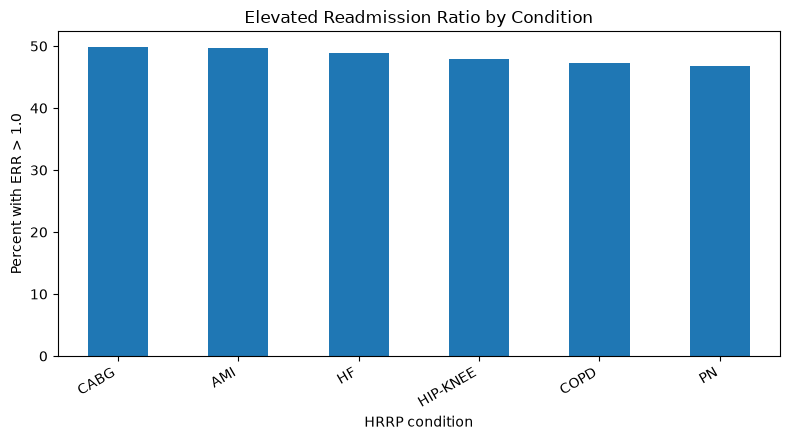

In [4]:
eda = df[df["elevated_err"].notna()].copy()

condition_summary = (eda.groupby("condition")["elevated_err"]
                     .agg(['mean','count'])
                     .rename(columns={'mean':'elevated_share','count':'n'})
                     .sort_values('elevated_share', ascending=False))
display(condition_summary)

ax = (condition_summary['elevated_share']*100).plot(kind='bar', figsize=(8,4.5))
ax.set_ylabel('Percent with ERR > 1.0')
ax.set_xlabel('HRRP condition')
ax.set_title('Elevated Readmission Ratio by Condition')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

,mean,count
state,,
NJ,0.654412,272
MA,0.625000,240
MS,0.610811,185
IL,0.578411,491
FL,0.574578,771
GA,0.557803,346
CA,0.552023,1038
KY,0.541850,227
WV,0.536842,95


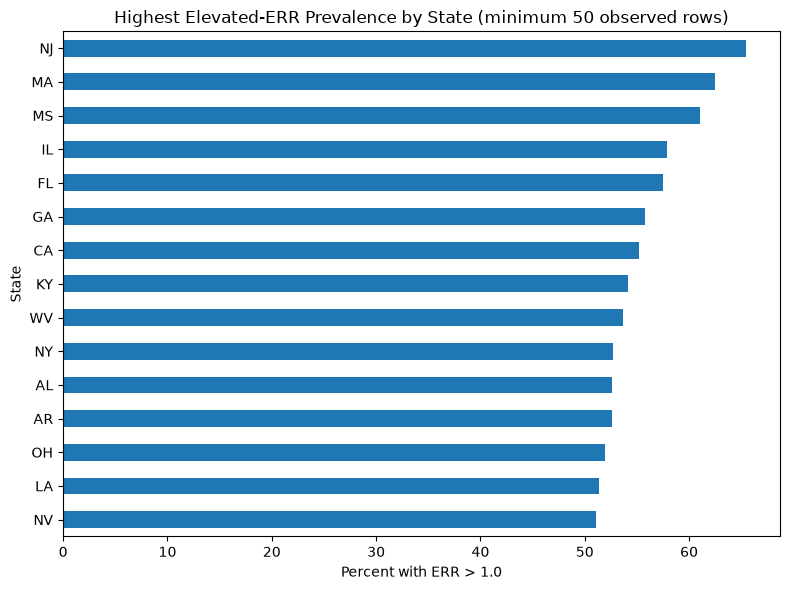

In [5]:
state_summary = (eda.groupby('state')['elevated_err']
                 .agg(['mean','count'])
                 .query('count >= 50')
                 .sort_values('mean', ascending=False))
display(state_summary.head(15))

ax = (state_summary.head(15)['mean']*100).sort_values().plot(kind='barh', figsize=(8,6))
ax.set_xlabel('Percent with ERR > 1.0')
ax.set_ylabel('State')
ax.set_title('Highest Elevated-ERR Prevalence by State (minimum 50 observed rows)')
plt.tight_layout()
plt.show()

### Interpretation of Descriptive Results

I found relatively little variation in elevated ERR prevalence across the six HRRP conditions, with rates clustered between approximately 47% and 50%. State-level variation was much larger. I interpret these differences as descriptive patterns rather than evidence that hospitals in one state provide better or worse care, because the analysis does not control for all clinical, socioeconomic, or structural differences across hospital populations.

## 4. Modeling approach

I compared two models for this analysis. I used logistic regression as an interpretable baseline and random forest as a nonlinear alternative that could capture interactions among the predictors.

I restricted the predictors to condition, state, and discharge volume. I excluded Facility ID and Facility Name from the predictor set and used Facility ID only to group hospitals during cross-validation. Facility name/ID are not used as predictors. Validation uses **StratifiedGroupKFold**, grouping on Facility ID so the same hospital cannot contribute records to both training and validation within a fold.

### Model Complexity and Tuning

I deferred hyperparameter tuning for this milestone because my goal was to compare a transparent baseline with a nonlinear alternative rather than optimize a production model. This keeps the comparison focused and reduces the risk of selecting settings that perform well only within the current validation design. Future work could tune candidate models using nested cross-validation or another appropriately separated validation process before considering production use.

In [6]:
model_df = df[df['elevated_err'].notna()].copy()
X = model_df[['condition','state','number_of_discharges']]
y = model_df['elevated_err'].astype(int)
groups = model_df['facility_id']

categorical = ['condition','state']
numeric = ['number_of_discharges']

preprocess = ColumnTransformer([
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical),
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), numeric)
])

models = {
    'Logistic regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                             class_weight='balanced_subsample',
                                             random_state=RANDOM_STATE, n_jobs=-1)
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'roc_auc':'roc_auc','pr_auc':'average_precision','precision':'precision',
           'recall':'recall','f1':'f1','balanced_accuracy':'balanced_accuracy'}

rows=[]
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    res = cross_validate(pipe, X, y, groups=groups, cv=cv, scoring=scoring, n_jobs=-1)
    row={'model':name}
    for metric in scoring:
        row[metric]=res[f'test_{metric}'].mean()
        row[f'{metric}_sd']=res[f'test_{metric}'].std()
    rows.append(row)

results = pd.DataFrame(rows).set_index('model').sort_values('roc_auc', ascending=False)
display(results.round(3))

,roc_auc,roc_auc_sd,pr_auc,pr_auc_sd,precision,precision_sd,recall,recall_sd,f1,f1_sd,balanced_accuracy,balanced_accuracy_sd
model,,,,,,,,,,,,
Random forest,0.663,0.011,0.654,0.012,0.592,0.007,0.577,0.017,0.584,0.010,0.604,0.007
Logistic regression,0.607,0.009,0.570,0.015,0.545,0.006,0.678,0.034,0.604,0.012,0.576,0.005


### Interpretation of Model Validation Results

The cross-validation results show that neither model dominates across every metric. The random forest achieved the stronger ROC-AUC and PR-AUC, indicating that it was better able to rank elevated-ERR observations above non-elevated observations across classification thresholds. However, logistic regression produced higher recall and F1 at the default 0.50 threshold.

I interpret this as an important operational tradeoff rather than evidence that one model is universally better. If the primary goal is to prioritize observations by overall risk, the random forest provides the stronger ranking model. If missing an elevated-ERR case is considered more costly than reviewing an additional false positive, the higher recall of logistic regression may be valuable. For this project, I selected random forest for the condition-specific analysis because ROC-AUC was established as the primary model-selection metric.

Random forest
              precision    recall  f1-score   support

           0      0.616     0.632     0.624      6077
           1      0.592     0.577     0.584      5643

    accuracy                          0.605     11720
   macro avg      0.604     0.604     0.604     11720
weighted avg      0.605     0.605     0.605     11720



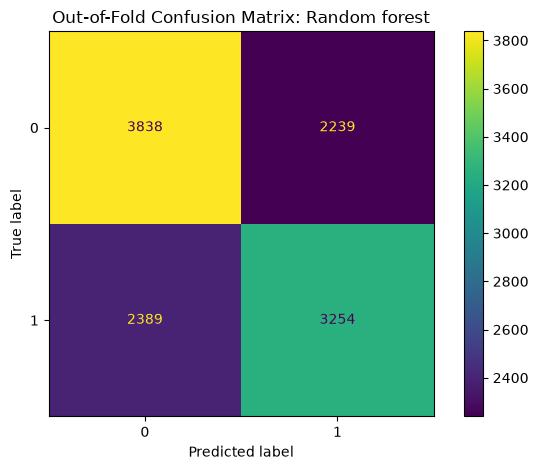

In [7]:
# Confusion matrix for the model selected by pooled ROC-AUC using out-of-fold predictions.
best_name = results.index[0]
best_model = models[best_name]
best_pipe = Pipeline([('prep', preprocess), ('model', best_model)])

oof_pred = cross_val_predict(best_pipe, X, y, groups=groups, cv=cv, method='predict', n_jobs=-1)
print(best_name)
print(classification_report(y, oof_pred, digits=3))

ConfusionMatrixDisplay(confusion_matrix(y, oof_pred)).plot(values_format='d')
plt.title(f'Out-of-Fold Confusion Matrix: {best_name}')
plt.tight_layout()
plt.show()

## 5. Condition-specific validation
A model can look acceptable overall while performing poorly for a specific HRRP condition. The next cell evaluates out-of-fold performance by condition. These results should be discussed as **classification performance**, not as evidence that a condition causes excess readmissions.

In [8]:
oof_prob = cross_val_predict(best_pipe, X, y, groups=groups, cv=cv, method='predict_proba', n_jobs=-1)[:,1]
check = model_df[['condition']].copy()
check['y_true'] = y.values
check['prob'] = oof_prob
check['pred'] = (oof_prob >= 0.5).astype(int)

by_condition=[]
for cond, g in check.groupby('condition'):
    if g['y_true'].nunique() < 2:
        continue
    by_condition.append({
        'condition':cond,
        'n':len(g),
        'roc_auc':roc_auc_score(g['y_true'],g['prob']),
        'pr_auc':average_precision_score(g['y_true'],g['prob']),
        'recall':recall_score(g['y_true'],g['pred']),
        'f1':f1_score(g['y_true'],g['pred'])
    })
by_condition = pd.DataFrame(by_condition).sort_values('roc_auc', ascending=False)
display(by_condition.round(3))

,condition,n,roc_auc,pr_auc,recall,f1
0,AMI,1736,0.698,0.709,0.607,0.620
5,PN,2715,0.674,0.645,0.571,0.584
2,COPD,2323,0.673,0.660,0.594,0.592
1,CABG,878,0.656,0.706,0.482,0.551
3,HF,2621,0.641,0.625,0.621,0.598
4,HIP-KNEE,1447,0.592,0.587,0.499,0.520


### Interpretation of Condition-Specific Performance

The condition-specific results show why I did not rely only on the pooled model score. Random forest ROC-AUC ranged from 0.592 for hip/knee replacement to 0.698 for acute myocardial infarction. AMI, pneumonia, and COPD showed the strongest discrimination, while hip/knee replacement was much closer to chance-level performance.

This variation suggests that a single national performance metric can hide important subgroup differences. I would therefore monitor performance separately by HRRP condition in any future implementation rather than assume that the pooled model performs equally well for every condition.

## 6. Interpretation and ethical checks
- Do not use the model to label a hospital as providing poor care.
- ERR is a program measure, not a causal estimate of care quality.
- Suppressed values are preserved as missing rather than imputed as observed outcomes.
- Because the model uses public hospital-level data, patient privacy risk is low; reputational, fairness, and validity risks are more important.
- Any operational use should include human review, condition-specific performance monitoring, and periodic re-validation after CMS data refreshes.

In [9]:
# Reproducibility summary
summary = {
    'rows_raw': len(df_raw),
    'rows_with_observed_err': int(df['excess_readmission_ratio'].notna().sum()),
    'unique_facilities': int(df['facility_id'].nunique()),
    'conditions': sorted(df['condition'].dropna().unique().tolist()),
    'model_rows': len(model_df),
    'target_prevalence': float(y.mean())
}
summary

{'rows_raw': 18330,
 'rows_with_observed_err': 11720,
 'unique_facilities': 3055,
 'conditions': ['AMI', 'CABG', 'COPD', 'HF', 'HIP-KNEE', 'PN'],
 'model_rows': 11720,
 'target_prevalence': 0.48148464163822524}

## 7. Save key outputs
These files can be used when building the final Milestone 3 presentation.

In [10]:
OUTPUT = Path('outputs')
OUTPUT.mkdir(exist_ok=True)
condition_summary.to_csv(OUTPUT/'condition_summary.csv')
state_summary.to_csv(OUTPUT/'state_summary.csv')
results.to_csv(OUTPUT/'model_validation_results.csv')
by_condition.to_csv(OUTPUT/'condition_validation_results.csv', index=False)
print('Saved outputs to', OUTPUT.resolve())

Saved outputs to C:\Users\socia\dsc680\outputs


### Dataset Reference

Centers for Medicare & Medicaid Services. (2026). *Hospital Readmissions Reduction Program* [Data set]. Provider Data Catalog. https://data.cms.gov/provider-data/dataset/9n3s-kdb3